### IMPORTS

In [41]:
import math
import numpy as np
import time
import matplotlib.pyplot as plt
import gc
import tracemalloc
import statistics

In [73]:
from platform import python_version
print(python_version())

3.12.13


### DualNumber Class

In [2]:
class DualNumber:
    # Use derivative = 0 as a defult so we can easily construct constants.
    def __init__(self, value, derivative=0.0):
        self.value = value
        self.derivative = derivative

    # Overload the '+' operator. This allows for DualNumber1 + DualNumber2 (or c).
    def __add__(self, other):
        # If other is not already a DualNumber, convert it to one.
        if not isinstance(other, DualNumber):
            other = self._convert(other)

        added_val = self.value + other.value
        added_derivative = self.derivative + other.derivative

        return DualNumber(added_val, added_derivative)

    # Allows for c + DualNumber1 by converting c to a DualNumber then adding.
    def __radd__(self, other):
        if not isinstance(other, DualNumber):
            other = self._convert(other)

        return other.__add__(self)

    # Overload the '-' operator. This allows for DualNumber1 - DualNumber2 (or c).
    def __sub__(self, other):
        # If other is not already a DualNumber, convert it to one.
        if not isinstance(other, DualNumber):
            other = self._convert(other)

        subtracted_val = self.value - other.value
        subtracted_derivative = self.derivative - other.derivative

        return DualNumber(subtracted_val, subtracted_derivative)

    # Allows for c - DualNumber1 by converting c to a DualNumber then subtracting.
    def __rsub__(self, other):
        # If other is not already a DualNumber, convert it to one.
        if not isinstance(other, DualNumber):
            other = self._convert(other)

        return other.__sub__(self)

    #Allows for DualNumber1 * DualNumber2 (or c)
    def __mul__(self, other):
        # If other is not already a DualNumber, convert it to one.
        if not isinstance(other, DualNumber):
            other = self._convert(other)

        multiplied_val = self.value * other.value
        # PRODUCT RULE (uv)' = uv' + vu'
        multiplied_derivative = (self.value * other.derivative) + (other.value * self.derivative)

        return DualNumber(multiplied_val, multiplied_derivative)

    # Allows for c * DualNumber1 by converting c to a DualNumber then multiplying.
    def __rmul__(self, other):
        if not isinstance(other, DualNumber):
            other = self._convert(other)

        return other.__mul__(self)

    #Allows for DualNumber1 / DualNumber2 (or c)
    def __truediv__(self, other):
        # If other is not already a DualNumber, convert it to one.
        if not isinstance(other, DualNumber):
            other = self._convert(other)

        divided_val = self.value / other.value
        # QUOTIENT RULE (u/v)' = (u'v - uv')/(v^2)
        divided_derivative = (
            (self.derivative * other.value - self.value * other.derivative) / (other.value * other.value)
        )

        return DualNumber(divided_val, divided_derivative)

    # Allows for c / DualNumber1 by converting c to a DualNumber then dividing.
    def __rtruediv__(self, other):
        if not isinstance(other, DualNumber):
            other = self._convert(other)

        return other.__truediv__(self)

    # Allows for DualNumber^n where n is an integer.
    def __pow__(self, power):
        powered_value = self.value ** power
        ##POWER RULE y^n = ny^{n-1} * dy/dx (w.r.t x)
        powered_derivative = power * self.value ** (power - 1) * self.derivative

        return DualNumber(powered_value, powered_derivative)

    def __neg__(self):
            return DualNumber(-self.value, -self.derivative)

    #Printing
    def __repr__(self):
        return (
            f"DualNumber("
            f"value={self.value:.6f}, "
            f"derivative={self.derivative:.6f}"
            f")"
        )

    # Allow conversion constant -> DualNumber
    @staticmethod
    def _convert(number):
        if isinstance(number, DualNumber):
            return number

        return DualNumber(number, 0.0)

In [3]:
x = DualNumber(2, 1)
f = 5*x**3 - 2*x**2 + x - 7
print(f)

DualNumber(value=27.000000, derivative=53.000000)


This can also handel partial derivitves such as:
$$ f(x,y) = x^2y + 3y $$

Say we want $f(2, 4)$:
$$f(2, 4) = 2^2(4) + 3(4) = 28$$
and 
$$ \frac{\partial f}{\partial y} = x^2 + 3$$
so 
$$\frac{\partial f}{\partial y}(x = 2) = 7.$$
and 
$$ \frac{\partial f}{\partial x} = 2xy$$
so 
$$ \frac{\partial f}{\partial x}(x = 2, y = 4) = 2(2)(4) = 16$$

In [ ]:
# Partial with respect to x: seed x=1, y=0
x = DualNumber(2, 1)
y = DualNumber(4, 0)

f = x**2 * y + 3*y

print("df/dx:")
print(f)

# Partial with respect to y: seed x=0, y=1
x = DualNumber(2, 0)
y = DualNumber(4, 1)

f = x**2 * y + 3*y

print("df/dy:")
print(f)

df/dx:
DualNumber(value=28.000000, derivative=16.000000)
df/dy:
DualNumber(value=28.000000, derivative=7.000000)


Now let's add more complex functions such as:
$$\sin{x}, \cos{x}, \exp{x}, \ln{x}$$

In [6]:
def forward_sin(x):
    if not isinstance(x, DualNumber):
        x = DualNumber._convert(x)

    new_value = math.sin(x.value)
    new_derivative = math.cos(x.value) * x.derivative

    return DualNumber(new_value, new_derivative)

def forward_cos(x):
    if not isinstance(x, DualNumber):
        x = DualNumber._convert(x)

    new_value = math.cos(x.value)
    new_derivative = -1 * math.sin(x.value) * x.derivative

    return DualNumber(new_value, new_derivative)
    

def forward_exp(x):
    if not isinstance(x, DualNumber):
        x = DualNumber._convert(x)

    new_value = math.exp(x.value)
    new_derivative = math.exp(x.value) * x.derivative

    return DualNumber(new_value, new_derivative)

def forward_ln(x):
    if not isinstance(x, DualNumber):
        x = DualNumber._convert(x)

    if x.value <= 0:
        raise ValueError("Undefined ln evaluation.")

    new_value = math.log(x.value)
    new_derivative = (1/x.value) * x.derivative

    return DualNumber(new_value, new_derivative)

In [7]:
x = DualNumber(0.5, 1)

print(forward_sin(x))
print(forward_cos(x))
print(forward_exp(x))
print(forward_ln(x))

DualNumber(value=0.479426, derivative=0.877583)
DualNumber(value=0.877583, derivative=-0.479426)
DualNumber(value=1.648721, derivative=1.648721)
DualNumber(value=-0.693147, derivative=2.000000)


In [8]:
x = DualNumber(2, 1)
y = DualNumber(3, 0)

f = forward_exp(x * y) + forward_sin(x**2)

print(f)

x = DualNumber(2, 0)
y = DualNumber(3, 1)

f = forward_exp(x * y) + forward_sin(x**2)

print(f)

DualNumber(value=402.671991, derivative=1207.671806)
DualNumber(value=402.671991, derivative=806.857587)


In [10]:
class ReverseNumber:

    def __init__(self, value, _children=()):

        self.value = value

        self.gradient = 0.0

        self._backward = lambda: None

        self._prev = set(_children)


    #Allows for ReverseNumber1 + ReverseNumber2 (or c)

    def __add__(self, other):

        # If other is not already a ReverseNumber, convert it to one.

        if not isinstance(other, ReverseNumber):

            other = self._convert(other)

        out = ReverseNumber(
            self.value + other.value,
            (self, other)
        )

        def _backward():

            # c = a + b

            # a = self

            # b = other

            # Local partials

            dc_da = 1.0  # partial c / partial a = 1

            dc_db = 1.0  # partial c / partial b = 1

            # Chain rule:

            # df/da += df/dc * dc/da

            # df/db += df/dc * dc/db

            self.gradient += out.gradient * dc_da

            other.gradient += out.gradient * dc_db

        out._backward = _backward

        return out


    # Allows for c + ReverseNumber1 by converting c to a ReverseNumber then adding.

    def __radd__(self, other):

        # If other is not already a ReverseNumber, convert it to one.

        if not isinstance(other, ReverseNumber):

            other = self._convert(other)

        return other.__add__(self)


    # Overload the '-' operator. This allows for ReverseNumber1 - ReverseNumber2 (or c).

    def __sub__(self, other):

        # If other is not already a ReverseNumber, convert it to one.

        if not isinstance(other, ReverseNumber):

            other = self._convert(other)

        out = ReverseNumber(
            self.value - other.value,
            (self, other)
        )

        def _backward():

            # c = a - b

            # a = self

            # b = other

            # Local partials

            dc_da = 1.0  # partial c / partial a = 1

            dc_db = -1.0  # partial c / partial b = -1

            # Chain rule:

            # df/da += df/dc * dc/da

            # df/db += df/dc * dc/db

            self.gradient += out.gradient * dc_da

            other.gradient += out.gradient * dc_db

        out._backward = _backward

        return out


    # Allows for c - ReverseNumber1 by converting c to a ReverseNumber then subtracting.

    def __rsub__(self, other):

        # If other is not already a ReverseNumber, convert it to one.

        if not isinstance(other, ReverseNumber):

            other = self._convert(other)

        return other.__sub__(self)


    #Allows for ReverseNumber1 * ReverseNumber2 (or c)

    def __mul__(self, other):

        # If other is not already a ReverseNumber, convert it to one.

        if not isinstance(other, ReverseNumber):

            other = self._convert(other)

        out = ReverseNumber(
            self.value * other.value,
            (self, other)
        )

        def _backward():

            # c = ab

            # a = self

            # b = other

            # Local partials

            dc_da = other.value

            dc_db = self.value

            # Chain rule:

            # df/da += df/dc * dc/da

            # df/db += df/dc * dc/db

            self.gradient += out.gradient * dc_da

            other.gradient += out.gradient * dc_db

        out._backward = _backward

        return out


    # Allows for c * ReverseNumber1 by converting c to a ReverseNumber then multiplying.

    def __rmul__(self, other):

        # If other is not already a ReverseNumber, convert it to one.

        if not isinstance(other, ReverseNumber):

            other = self._convert(other)

        return other.__mul__(self)


    #Allows for ReverseNumber1 / ReverseNumber2 (or c)

    def __truediv__(self, other):

        # If other is not already a ReverseNumber, convert it to one.

        if not isinstance(other, ReverseNumber):

            other = self._convert(other)

        out = ReverseNumber(
            self.value / other.value,
            (self, other)
        )

        def _backward():

            # c = a / b

            # a = self

            # b = other

            # Local partials

            dc_da = 1.0 / other.value

            dc_db = -self.value / (other.value ** 2)

            # Chain rule:

            # df/da += df/dc * dc/da

            # df/db += df/dc * dc/db

            self.gradient += out.gradient * dc_da

            other.gradient += out.gradient * dc_db

        out._backward = _backward

        return out


    # Allows for c / ReverseNumber1 by converting c to a ReverseNumber then dividing.

    def __rtruediv__(self, other):

        # If other is not already a ReverseNumber, convert it to one.

        if not isinstance(other, ReverseNumber):

            other = self._convert(other)

        return other.__truediv__(self)


    # Allows for ReverseNumber^n where n is an integer.

    def __pow__(self, power):

        out = ReverseNumber(
            self.value ** power,
            (self,)
        )

        def _backward():

            # c = a^n

            # a = self

            # Local partial

            # POWER RULE dc/da = n*a^(n-1)

            dc_da = power * self.value ** (power - 1)

            # Chain rule:

            # df/da += df/dc * dc/da

            self.gradient += out.gradient * dc_da

        out._backward = _backward

        return out


    def __neg__(self):

        out = ReverseNumber(
            -self.value,
            (self,)
        )

        def _backward():

            # c = -a

            # a = self

            # Local partial

            dc_da = -1.0

            # Chain rule:

            # df/da += df/dc * dc/da

            self.gradient += out.gradient * dc_da

        out._backward = _backward

        return out


    # Run reverse-mode automatic differentiation.

    def backward(self):

        # Build a topological ordering of the computational graph.

        topo = []

        visited = set()

        def build_topological_order(node):

            if node not in visited:

                visited.add(node)

                for parent in node._prev:

                    build_topological_order(parent)

                topo.append(node)

        build_topological_order(self)

        # Seed the final output.

        # partial f / partial f = 1

        self.gradient = 1.0

        # Traverse the graph backwards.

        # Each node passes its current gradient backwards to its parents.

        for node in reversed(topo):

            node._backward()


    #Printing

    def __repr__(self):

        return (
            f"ReverseNumber("
            f"value={self.value:.6f}, "
            f"gradient={self.gradient:.6f}"
            f")"
        )


    # Allow conversion constant -> ReverseNumber

    @staticmethod

    def _convert(number):

        if isinstance(number, ReverseNumber):

            return number

        return ReverseNumber(number)

Now let's add more complex functions such as:
$$\sin{x}, \cos{x}, \exp{x}, \ln{x}$$

In [16]:
def reverse_sin(x):

    if not isinstance(x, ReverseNumber):

        x = ReverseNumber._convert(x)

    out = ReverseNumber(
        math.sin(x.value),
        (x,)
    )

    def _backward():

        # c = sin(a)

        # a = x

        # Local partial

        dc_da = math.cos(x.value)

        # Chain rule:

        # df/da += df/dc * dc/da

        x.gradient += out.gradient * dc_da

    out._backward = _backward

    return out


def reverse_cos(x):

    if not isinstance(x, ReverseNumber):

        x = ReverseNumber._convert(x)

    out = ReverseNumber(
        math.cos(x.value),
        (x,)
    )

    def _backward():

        # c = cos(a)

        # a = x

        # Local partial

        dc_da = -math.sin(x.value)

        # Chain rule:

        # df/da += df/dc * dc/da

        x.gradient += out.gradient * dc_da

    out._backward = _backward

    return out


def reverse_exp(x):

    if not isinstance(x, ReverseNumber):

        x = ReverseNumber._convert(x)

    out = ReverseNumber(
        math.exp(x.value),
        (x,)
    )

    def _backward():

        # c = exp(a)

        # a = x

        # Local partial

        dc_da = math.exp(x.value)

        # Chain rule:

        # df/da += df/dc * dc/da

        x.gradient += out.gradient * dc_da

    out._backward = _backward

    return out


def reverse_ln(x):

    if not isinstance(x, ReverseNumber):

        x = ReverseNumber._convert(x)

    if x.value <= 0:

        raise ValueError("Undefined ln evaluation.")

    out = ReverseNumber(
        math.log(x.value),
        (x,)
    )

    def _backward():

        # c = ln(a)

        # a = x

        # Local partial

        dc_da = 1 / x.value

        # Chain rule:

        # df/da += df/dc * dc/da

        x.gradient += out.gradient * dc_da

    out._backward = _backward

    return out

Now we do some correctness tests. We will use the expression:

$$f(x,y) = e^{xy} + \sin{x^2}$$

Computing the partial derivitves:

$$ \frac{\partial f}{\partial x} = ye^{xy} + 2x \cos{x^2} $$

and,

$$\frac{\partial f}{\partial y} = xe^{xy}$$

We will evaluate $f(2,3)$, $\frac{\partial f}{\partial x}(2,3)$ and $\frac{\partial f}{\partial y}(2,3)$ 

In [12]:
# Test point
x_val = 2.0
y_val = 3.0

# Analytical function value
f_true = np.exp(x_val * y_val) + np.sin(x_val ** 2)

# Analytical derivatives
df_dx_true = (
    y_val * np.exp(x_val * y_val)
    + 2 * x_val * np.cos(x_val ** 2)
)

df_dy_true = x_val * np.exp(x_val * y_val)

print("Analytical:")
print("f =", f_true)
print("df/dx =", df_dx_true)
print("df/dy =", df_dy_true)

Analytical:
f = 402.6719909974272
df/dx = 1207.671805994751
df/dy = 806.8575869854702


In [14]:
# Forward mode: derivative with respect to x

x = DualNumber(x_val, 1.0)
y = DualNumber(y_val, 0.0)

f_x = forward_exp(x * y) + forward_sin(x ** 2)

print("\nForward mode, seeded for x:")
print("f =", f_x.value)
print("df/dx =", f_x.derivative)


# Forward mode: derivative with respect to y

x = DualNumber(x_val, 0.0)
y = DualNumber(y_val, 1.0)

f_y = forward_exp(x * y) + forward_sin(x ** 2)

print("\nForward mode, seeded for y:")
print("f =", f_y.value)
print("df/dy =", f_y.derivative)


Forward mode, seeded for x:
f = 402.6719909974272
df/dx = 1207.671805994751

Forward mode, seeded for y:
f = 402.6719909974272
df/dy = 806.8575869854702


In [17]:
# Reverse mode

x = ReverseNumber(x_val)
y = ReverseNumber(y_val)

f = reverse_exp(x * y) + reverse_sin(x ** 2)

f.backward()

print("\nReverse mode:")
print("f =", f.value)
print("df/dx =", x.gradient)
print("df/dy =", y.gradient)


Reverse mode:
f = 402.6719909974272
df/dx = 1207.671805994751
df/dy = 806.8575869854702


In [18]:
print("\nCorrectness checks:")

print(
    "Forward df/dx correct:",
    np.isclose(f_x.derivative, df_dx_true)
)

print(
    "Forward df/dy correct:",
    np.isclose(f_y.derivative, df_dy_true)
)

print(
    "Reverse df/dx correct:",
    np.isclose(x.gradient, df_dx_true)
)

print(
    "Reverse df/dy correct:",
    np.isclose(y.gradient, df_dy_true)
)


Correctness checks:
Forward df/dx correct: True
Forward df/dy correct: True
Reverse df/dx correct: True
Reverse df/dy correct: True


Now we do a second correctness test using a different combination of operations:

$$f(x,y) = \ln(xy) + \cos(x^2)$$

Computing the partial derivatives:

$$\frac{\partial f}{\partial x} = \frac{1}{x} - 2x\sin(x^2)$$

and,

$$\frac{\partial f}{\partial y} = \frac{1}{y}$$

We will evaluate $f(2,3)$, $\frac{\partial f}{\partial x}(2,3)$ and $\frac{\partial f}{\partial y}(2,3)$.

In [19]:
# Test point
x_val = 2.0
y_val = 3.0

# Analytical function value
f_true = np.log(x_val * y_val) + np.cos(x_val ** 2)

# Analytical derivatives
df_dx_true = (
    1 / x_val
    - 2 * x_val * np.sin(x_val ** 2)
)

df_dy_true = 1 / y_val

print("Analytical:")
print("f =", f_true)
print("df/dx =", df_dx_true)
print("df/dy =", df_dy_true)

Analytical:
f = 1.1381158483644431
df/dx = 3.5272099812317133
df/dy = 0.3333333333333333


In [20]:
# Forward mode: derivative with respect to x

x = DualNumber(x_val, 1.0)
y = DualNumber(y_val, 0.0)

f_x = forward_ln(x * y) + forward_cos(x ** 2)

print("\nForward mode, seeded for x:")
print("f =", f_x.value)
print("df/dx =", f_x.derivative)


# Forward mode: derivative with respect to y

x = DualNumber(x_val, 0.0)
y = DualNumber(y_val, 1.0)

f_y = forward_ln(x * y) + forward_cos(x ** 2)

print("\nForward mode, seeded for y:")
print("f =", f_y.value)
print("df/dy =", f_y.derivative)


Forward mode, seeded for x:
f = 1.1381158483644431
df/dx = 3.5272099812317133

Forward mode, seeded for y:
f = 1.1381158483644431
df/dy = 0.3333333333333333


In [21]:
# Reverse mode

x = ReverseNumber(x_val)
y = ReverseNumber(y_val)

f = reverse_ln(x * y) + reverse_cos(x ** 2)

f.backward()

print("\nReverse mode:")
print("f =", f.value)
print("df/dx =", x.gradient)
print("df/dy =", y.gradient)


Reverse mode:
f = 1.1381158483644431
df/dx = 3.5272099812317133
df/dy = 0.3333333333333333


In [22]:
print("\nCorrectness checks:")

print(
    "Forward df/dx correct:",
    np.isclose(f_x.derivative, df_dx_true)
)

print(
    "Forward df/dy correct:",
    np.isclose(f_y.derivative, df_dy_true)
)

print(
    "Reverse df/dx correct:",
    np.isclose(x.gradient, df_dx_true)
)

print(
    "Reverse df/dy correct:",
    np.isclose(y.gradient, df_dy_true)
)


Correctness checks:
Forward df/dx correct: True
Forward df/dy correct: True
Reverse df/dx correct: True
Reverse df/dy correct: True


Now we compare the runtime of forward-mode and reverse-mode automatic differentiation when computing the full gradient of a scalar-valued function with an increasing number of inputs.

We use the function:

$$
f(x_1,\dots,x_n)
=
\sum_{i=1}^{n}
\left(
\sin(x_i)+0.01x_i^2
\right)
$$

For forward-mode automatic differentiation, computing the full gradient requires one seeded forward pass for each input variable.

For reverse-mode automatic differentiation, the computational graph is constructed once and a single backward pass computes the derivatives with respect to all input variables.

We will measure the runtime required to compute the complete gradient as the number of input variables increases.

In [23]:
def forward_full_gradient(values):

    gradient = []

    n = len(values)

    # One seeded forward pass for each input variable
    for seed_index in range(n):

        dual_inputs = []

        for i, value in enumerate(values):

            if i == seed_index:

                dual_inputs.append(DualNumber(value, 1.0))

            else:

                dual_inputs.append(DualNumber(value, 0.0))

        f = DualNumber(0.0, 0.0)

        for x in dual_inputs:

            f = f + forward_sin(x) + 0.01 * (x ** 2)

        gradient.append(f.derivative)

    return gradient

In [24]:
def reverse_full_gradient(values):

    reverse_inputs = [
        ReverseNumber(value)
        for value in values
    ]

    f = ReverseNumber(0.0)

    for x in reverse_inputs:

        f = f + reverse_sin(x) + 0.01 * (x ** 2)

    f.backward()

    gradient = [
        x.gradient
        for x in reverse_inputs
    ]

    return gradient

In [25]:
values = [0.5, 1.0, 1.5]

print(forward_full_gradient(values))
print(reverse_full_gradient(values))

[0.8875825618903728, 0.5603023058681398, 0.1007372016677029]
[0.8875825618903728, 0.5603023058681398, 0.1007372016677029]


In [36]:

sizes = [100, 250, 400, 625, 1250]

forward_times = []
reverse_times = []

repeats = 5

for n in sizes:

    values = np.linspace(0.1, 1.0, n).tolist()

    # Forward mode timings
    forward_runs = []

    for _ in range(repeats):

        start = time.perf_counter()

        forward_full_gradient(values)

        end = time.perf_counter()

        forward_runs.append(end - start)

    # Reverse mode timings
    reverse_runs = []

    for _ in range(repeats):

        start = time.perf_counter()

        reverse_full_gradient(values)

        end = time.perf_counter()

        reverse_runs.append(end - start)

    # Use median to reduce timing noise
    forward_times.append(np.median(forward_runs))

    reverse_times.append(np.median(reverse_runs))


print("n values:", sizes)

print("Forward median times:", forward_times)

print("Reverse median times:", reverse_times)

n values: [100, 250, 400, 625, 1250]
Forward median times: [np.float64(0.01043875003233552), np.float64(0.05937791703036055), np.float64(0.15595220896648243), np.float64(0.37051800003973767), np.float64(1.5681771670351736)]
Reverse median times: [np.float64(0.0004217500099912286), np.float64(0.0015323749976232648), np.float64(0.0023692920221947134), np.float64(0.003433041973039508), np.float64(0.007757082988973707)]


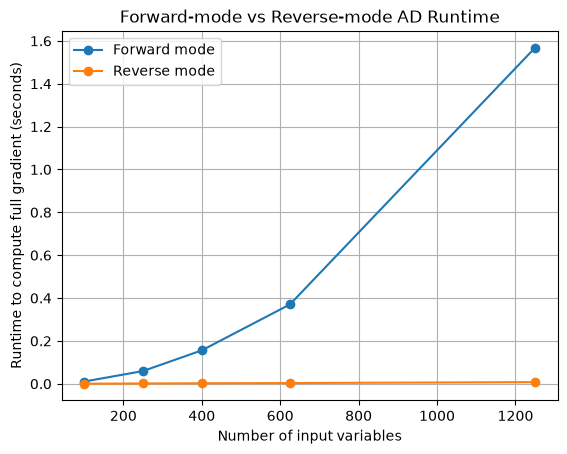

In [38]:
plt.plot(
    sizes,
    forward_times,
    marker="o",
    label="Forward mode"
)

plt.plot(
    sizes,
    reverse_times,
    marker="o",
    label="Reverse mode"
)

plt.xlabel("Number of input variables")

plt.ylabel("Runtime to compute full gradient (seconds)")

plt.title("Forward-mode vs Reverse-mode AD Runtime")

plt.legend()

plt.grid()

plt.show()

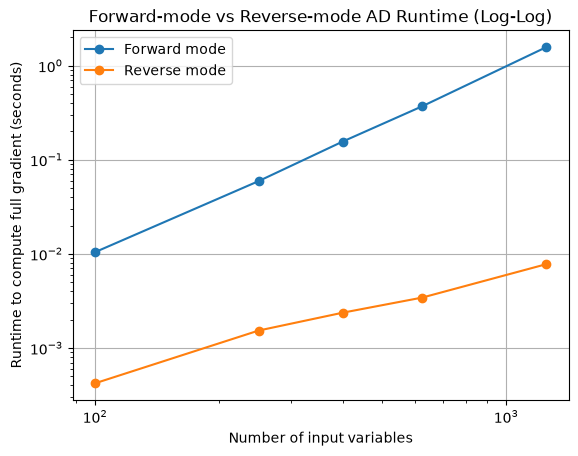

In [39]:
plt.loglog(
    sizes,
    forward_times,
    marker="o",
    label="Forward mode"
)

plt.loglog(
    sizes,
    reverse_times,
    marker="o",
    label="Reverse mode"
)

plt.xlabel("Number of input variables")

plt.ylabel("Runtime to compute full gradient (seconds)")

plt.title("Forward-mode vs Reverse-mode AD Runtime (Log-Log)")

plt.legend()

plt.grid()

plt.show()

In [40]:
forward_slope = np.polyfit(
    np.log(sizes),
    np.log(forward_times),
    1
)[0]

reverse_slope = np.polyfit(
    np.log(sizes),
    np.log(reverse_times),
    1
)[0]

print("Forward empirical scaling exponent:", forward_slope)
print("Reverse empirical scaling exponent:", reverse_slope)

Forward empirical scaling exponent: 1.9836180296862058
Reverse empirical scaling exponent: 1.125794375925233


Now let us test memory usage between forward and backward AD modes.

In [49]:
def measure_peak_memory(function, values):
    gc.collect()

    tracemalloc.start()

    function(values)

    current, peak = tracemalloc.get_traced_memory()

    tracemalloc.stop()

    # Convert bytes to KiB
    return peak / 1024

In [50]:
forward_memory = []
reverse_memory = []

for n in sizes:

    values = [
        0.5 + 0.001 * i
        for i in range(n)
    ]

    forward_runs = []
    reverse_runs = []

    for _ in range(5):

        forward_runs.append(
            measure_peak_memory(
                forward_full_gradient,
                values
            )
        )

        reverse_runs.append(
            measure_peak_memory(
                reverse_full_gradient,
                values
            )
        )

    forward_memory.append(
        statistics.median(forward_runs)
    )

    reverse_memory.append(
        statistics.median(reverse_runs)
    )

In [51]:
for i in range(len(sizes)):

    print(
        f"n = {sizes[i]} | "
        f"Forward = {forward_memory[i]:.2f} KiB | "
        f"Reverse = {reverse_memory[i]:.2f} KiB"
    )

n = 10 | Forward = 2.38 KiB | Reverse = 47.76 KiB
n = 25 | Forward = 4.33 KiB | Reverse = 120.37 KiB
n = 50 | Forward = 7.69 KiB | Reverse = 256.41 KiB
n = 100 | Forward = 14.42 KiB | Reverse = 476.98 KiB
n = 200 | Forward = 27.58 KiB | Reverse = 1019.43 KiB
n = 400 | Forward = 54.23 KiB | Reverse = 1901.95 KiB


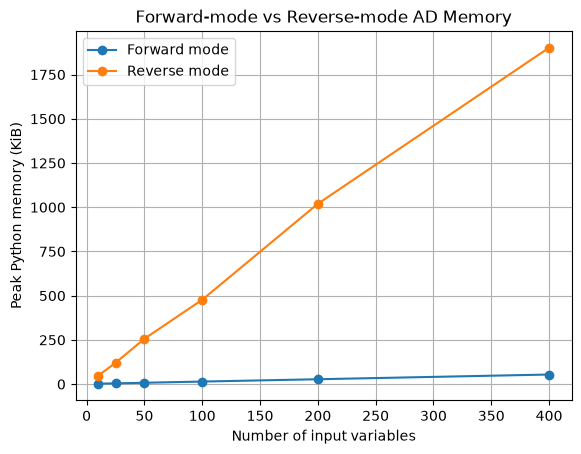

In [52]:
plt.plot(
    sizes,
    forward_memory,
    marker="o",
    label="Forward mode"
)

plt.plot(
    sizes,
    reverse_memory,
    marker="o",
    label="Reverse mode"
)

plt.xlabel("Number of input variables")

plt.ylabel("Peak Python memory (KiB)")

plt.title("Forward-mode vs Reverse-mode AD Memory")

plt.legend()

plt.grid()

plt.show()

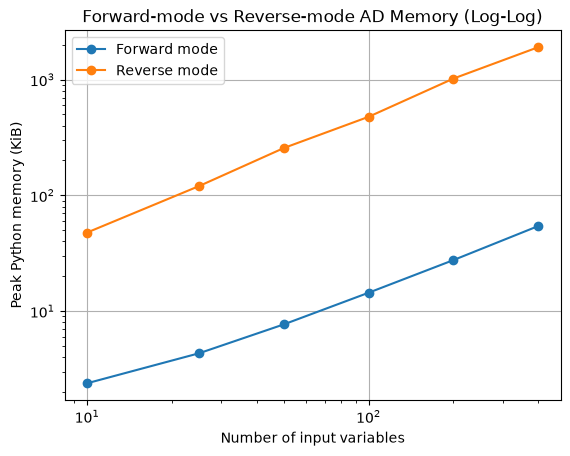

In [53]:
plt.loglog(
    sizes,
    forward_memory,
    marker="o",
    label="Forward mode"
)

plt.loglog(
    sizes,
    reverse_memory,
    marker="o",
    label="Reverse mode"
)

plt.xlabel("Number of input variables")

plt.ylabel("Peak Python memory (KiB)")

plt.title("Forward-mode vs Reverse-mode AD Memory (Log-Log)")

plt.legend()

plt.grid()

plt.show()

In [54]:
forward_memory_slope = np.polyfit(
    np.log(sizes),
    np.log(forward_memory),
    1
)[0]


reverse_memory_slope = np.polyfit(
    np.log(sizes),
    np.log(reverse_memory),
    1
)[0]


print(
    "Forward empirical memory scaling exponent:",
    forward_memory_slope
)

print(
    "Reverse empirical memory scaling exponent:",
    reverse_memory_slope
)

Forward empirical memory scaling exponent: 0.8564144276349243
Reverse empirical memory scaling exponent: 1.0034399829639846


Now let us test checkpointing

Here we use:
$$x_{i + 1} = \sin{x_i} + 0.01x_i^2$$
with local derivative:
$$\frac{dx_{i + 1}}{dx_{i}} = \cos{x_i} + 0.02x_i$$

In [55]:
def step(x):
    return math.sin(x) + 0.01 * x**2


def step_derivative(x):
    return math.cos(x) + 0.02 * x

In [57]:
def full_storage(x0, depth):

    values = [x0]

    x = x0

    # Forward pass
    for _ in range(depth):
        x = step(x)
        values.append(x)

    output = x


    # Backward pass
    gradient = 1.0

    for i in range(depth - 1, -1, -1):
        gradient *= step_derivative(values[i])


    return output, gradient, len(values)

In [58]:
def checkpointed_storage(x0, depth, checkpoint_interval):

    # Which states will be permanently stored?
    checkpoint_indices = list(
        range(0, depth + 1, checkpoint_interval)
    )

    # Always store the final state
    if checkpoint_indices[-1] != depth:
        checkpoint_indices.append(depth)


    # ---------------------------------
    # Forward pass
    # ---------------------------------

    checkpoints = [x0]

    x = x0
    next_checkpoint = 1

    for i in range(1, depth + 1):

        x = step(x)

        if (
            next_checkpoint < len(checkpoint_indices)
            and i == checkpoint_indices[next_checkpoint]
        ):
            checkpoints.append(x)
            next_checkpoint += 1

    output = x


    # ---------------------------------
    # Backward pass
    # ---------------------------------

    gradient = 1.0
    recomputed_values = 0

    peak_stored_values = len(checkpoints)


    # Process checkpoint blocks backwards
    for block in range(
        len(checkpoint_indices) - 1,
        0,
        -1
    ):

        start_index = checkpoint_indices[block - 1]
        end_index = checkpoint_indices[block]

        x = checkpoints[block - 1]

        # Temporarily rebuild the missing values
        block_values = [x]

        for _ in range(start_index + 1, end_index):

            x = step(x)

            block_values.append(x)

            recomputed_values += 1


        # Estimate peak number of values held at once
        current_stored_values = (
            len(checkpoints)
            + len(block_values)
            - 1
        )

        peak_stored_values = max(
            peak_stored_values,
            current_stored_values
        )


        # Backpropagate through this reconstructed block
        for value in reversed(block_values):

            gradient *= step_derivative(value)


    return (
        output,
        gradient,
        len(checkpoints),
        recomputed_values,
        peak_stored_values
    )

In [59]:
x0 = 0.5
depth = 10000

full_output, full_gradient, full_stored = full_storage(
    x0,
    depth
)

checkpoint_output, checkpoint_gradient, checkpoints, recomputed, peak_proxy = checkpointed_storage(
    x0,
    depth,
    checkpoint_interval=100
)

print("Full output:", full_output)
print("Checkpoint output:", checkpoint_output)

print()

print("Full gradient:", full_gradient)
print("Checkpoint gradient:", checkpoint_gradient)

print()

print("Full stored values:", full_stored)
print("Checkpoints:", checkpoints)
print("Recomputed values:", recomputed)
print("Peak storage proxy:", peak_proxy)

Full output: 0.060065079137691546
Checkpoint output: 0.060065079137691546

Full gradient: 1.700276496195812e-06
Checkpoint gradient: 1.700276496195812e-06

Full stored values: 10001
Checkpoints: 101
Recomputed values: 9900
Peak storage proxy: 200


In [60]:
intervals = [
    1,
    2,
    5,
    10,
    20,
    50,
    100,
    200,
    500,
    1000,
    10000
]

checkpoint_results = []


for interval in intervals:

    runtimes = []

    for _ in range(5):

        start = time.perf_counter()

        result = checkpointed_storage(
            x0=0.5,
            depth=10000,
            checkpoint_interval=interval
        )

        end = time.perf_counter()

        runtimes.append(end - start)


    output, gradient, checkpoints, recomputed, peak_proxy = result


    checkpoint_results.append({
        "interval": interval,
        "runtime": statistics.median(runtimes),
        "checkpoints": checkpoints,
        "recomputed": recomputed,
        "peak_proxy": peak_proxy
    })

In [61]:
for result in checkpoint_results:
    print(result)

{'interval': 1, 'runtime': 0.00467675004620105, 'checkpoints': 10001, 'recomputed': 0, 'peak_proxy': 10001}
{'interval': 2, 'runtime': 0.0031915830331854522, 'checkpoints': 5001, 'recomputed': 5000, 'peak_proxy': 5002}
{'interval': 5, 'runtime': 0.0026465420378372073, 'checkpoints': 2001, 'recomputed': 8000, 'peak_proxy': 2005}
{'interval': 10, 'runtime': 0.002445499994792044, 'checkpoints': 1001, 'recomputed': 9000, 'peak_proxy': 1010}
{'interval': 20, 'runtime': 0.0023170830099843442, 'checkpoints': 501, 'recomputed': 9500, 'peak_proxy': 520}
{'interval': 50, 'runtime': 0.0021665000240318477, 'checkpoints': 201, 'recomputed': 9800, 'peak_proxy': 250}
{'interval': 100, 'runtime': 0.0022490830160677433, 'checkpoints': 101, 'recomputed': 9900, 'peak_proxy': 200}
{'interval': 200, 'runtime': 0.002204999967943877, 'checkpoints': 51, 'recomputed': 9950, 'peak_proxy': 250}
{'interval': 500, 'runtime': 0.0021782080293633044, 'checkpoints': 21, 'recomputed': 9980, 'peak_proxy': 520}
{'interva

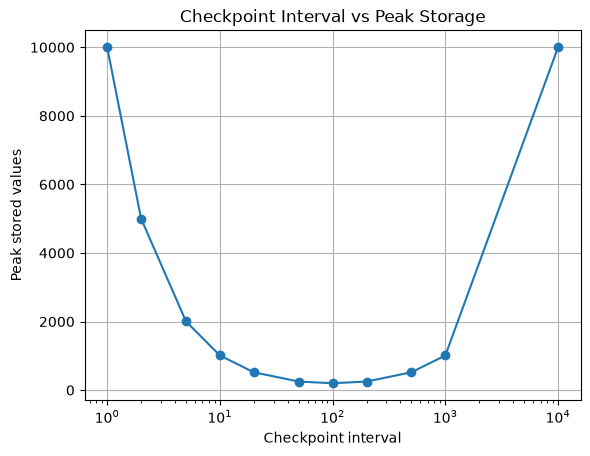

In [62]:
intervals_plot = [
    result["interval"]
    for result in checkpoint_results
]

peak_storage = [
    result["peak_proxy"]
    for result in checkpoint_results
]


plt.plot(
    intervals_plot,
    peak_storage,
    marker="o"
)

plt.xscale("log")

plt.xlabel("Checkpoint interval")
plt.ylabel("Peak stored values")

plt.title("Checkpoint Interval vs Peak Storage")

plt.grid()

plt.show()

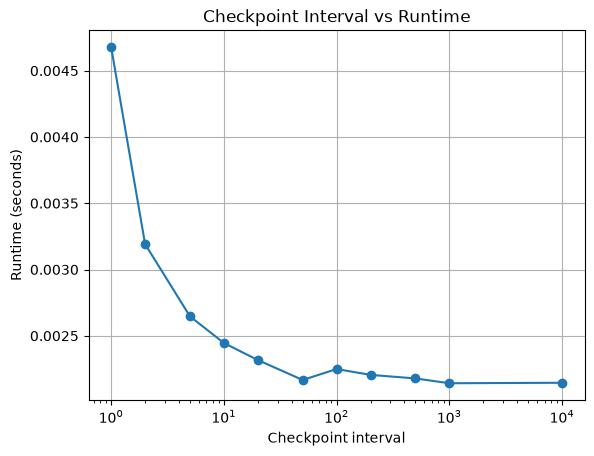

In [63]:
runtimes = [
    result["runtime"]
    for result in checkpoint_results
]


plt.plot(
    intervals_plot,
    runtimes,
    marker="o"
)

plt.xscale("log")

plt.xlabel("Checkpoint interval")
plt.ylabel("Runtime (seconds)")

plt.title("Checkpoint Interval vs Runtime")

plt.grid()

plt.show()

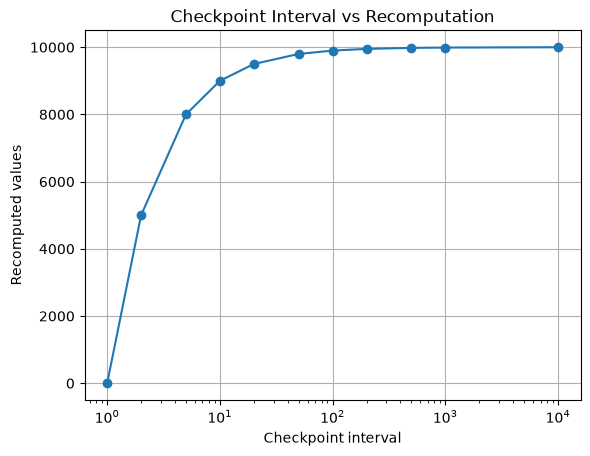

In [64]:
recomputed = [
    result["recomputed"]
    for result in checkpoint_results
]


plt.plot(
    intervals_plot,
    recomputed,
    marker="o"
)

plt.xscale("log")

plt.xlabel("Checkpoint interval")
plt.ylabel("Recomputed values")

plt.title("Checkpoint Interval vs Recomputation")

plt.grid()

plt.show()

In [65]:
def measure_checkpoint_memory(x0, depth, checkpoint_interval):
    gc.collect()

    tracemalloc.start()

    checkpointed_storage(
        x0=x0,
        depth=depth,
        checkpoint_interval=checkpoint_interval
    )

    current, peak = tracemalloc.get_traced_memory()

    tracemalloc.stop()

    return peak / 1024

In [66]:
checkpoint_memory = []

for interval in intervals:

    runs = []

    for _ in range(5):
        runs.append(
            measure_checkpoint_memory(
                x0=0.5,
                depth=10000,
                checkpoint_interval=interval
            )
        )

    checkpoint_memory.append(
        statistics.median(runs)
    )

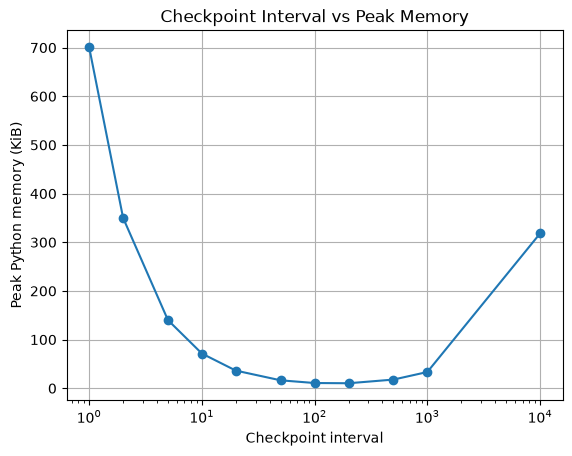

In [67]:
plt.plot(
    intervals,
    checkpoint_memory,
    marker="o"
)

plt.xscale("log")

plt.xlabel("Checkpoint interval")
plt.ylabel("Peak Python memory (KiB)")

plt.title("Checkpoint Interval vs Peak Memory")

plt.grid()

plt.show()

In [68]:
depths = [
    2500,
    5000,
    10000,
    20000
]

depth_results = []


for depth in depths:

    predicted_interval = math.sqrt(depth)

    # Test intervals around the sqrt(L) prediction
    test_intervals = [
        max(1, round(predicted_interval * 0.25)),
        max(1, round(predicted_interval * 0.5)),
        max(1, round(predicted_interval * 0.75)),
        max(1, round(predicted_interval)),
        max(1, round(predicted_interval * 1.5)),
        max(1, round(predicted_interval * 2)),
        max(1, round(predicted_interval * 3)),
        max(1, round(predicted_interval * 4))
    ]

    # Remove any duplicates
    test_intervals = sorted(set(test_intervals))


    best_interval = None
    best_memory = float("inf")

    measurements = []


    for interval in test_intervals:

        runs = []

        for _ in range(5):

            memory = measure_checkpoint_memory(
                x0=0.5,
                depth=depth,
                checkpoint_interval=interval
            )

            runs.append(memory)


        median_memory = statistics.median(runs)

        measurements.append(
            (interval, median_memory)
        )


        if median_memory < best_memory:
            best_memory = median_memory
            best_interval = interval


    depth_results.append({
        "depth": depth,
        "predicted_interval": predicted_interval,
        "best_interval": best_interval,
        "best_memory": best_memory,
        "measurements": measurements
    })

In [69]:
for result in depth_results:

    print(
        f"Depth = {result['depth']} | "
        f"sqrt(L) = {result['predicted_interval']:.2f} | "
        f"Best measured interval = {result['best_interval']} | "
        f"Peak memory = {result['best_memory']:.2f} KiB"
    )

Depth = 2500 | sqrt(L) = 50.00 | Best measured interval = 75 | Peak memory = 5.31 KiB
Depth = 5000 | sqrt(L) = 70.71 | Best measured interval = 106 | Peak memory = 7.28 KiB
Depth = 10000 | sqrt(L) = 100.00 | Best measured interval = 150 | Peak memory = 10.13 KiB
Depth = 20000 | sqrt(L) = 141.42 | Best measured interval = 212 | Peak memory = 14.12 KiB


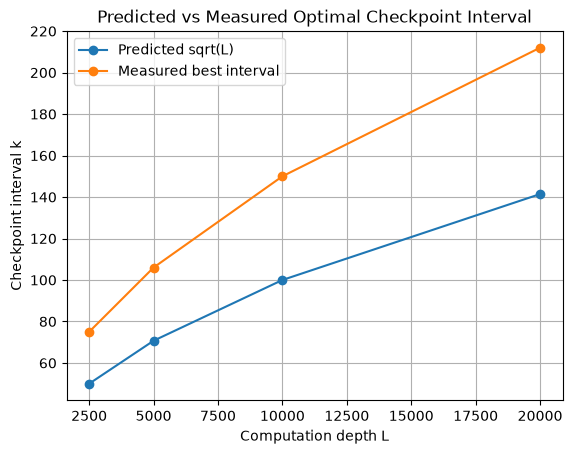

In [70]:
predicted_intervals = [
    result["predicted_interval"]
    for result in depth_results
]

measured_intervals = [
    result["best_interval"]
    for result in depth_results
]


plt.plot(
    depths,
    predicted_intervals,
    marker="o",
    label="Predicted sqrt(L)"
)

plt.plot(
    depths,
    measured_intervals,
    marker="o",
    label="Measured best interval"
)

plt.xlabel("Computation depth L")
plt.ylabel("Checkpoint interval k")

plt.title("Predicted vs Measured Optimal Checkpoint Interval")

plt.legend()
plt.grid()

plt.show()

In [71]:
depths = [
    2500,
    5000,
    10000,
    20000
]

final_depth_results = []


for depth in depths:

    predicted = math.sqrt(depth)

    # Search a dense range instead of only fixed multiples
    max_interval = round(3 * predicted)

    test_intervals = range(
        10,
        max_interval + 1,
        5
    )


    best_interval = None
    best_memory = float("inf")


    for interval in test_intervals:

        runs = []

        for _ in range(5):

            memory = measure_checkpoint_memory(
                x0=0.5,
                depth=depth,
                checkpoint_interval=interval
            )

            runs.append(memory)


        median_memory = statistics.median(runs)


        if median_memory < best_memory:

            best_memory = median_memory
            best_interval = interval


    final_depth_results.append({
        "depth": depth,
        "predicted": predicted,
        "measured": best_interval,
        "memory": best_memory
    })

In [72]:
for result in final_depth_results:

    print(
        f"L = {result['depth']} | "
        f"sqrt(L) = {result['predicted']:.2f} | "
        f"Measured optimum = {result['measured']} | "
        f"Ratio = {result['measured'] / result['predicted']:.2f}"
    )

L = 2500 | sqrt(L) = 50.00 | Measured optimum = 70 | Ratio = 1.40
L = 5000 | sqrt(L) = 70.71 | Measured optimum = 100 | Ratio = 1.41
L = 10000 | sqrt(L) = 100.00 | Measured optimum = 145 | Ratio = 1.45
L = 20000 | sqrt(L) = 141.42 | Measured optimum = 230 | Ratio = 1.63
